# **Hälsostudie del 1**

### Grundläggande analys och stastistik

i den här uppgiften ska man analysera data från hälsostudie med hjälp av pythin. Datasetet innehåller infrormation om deltagarnas ålder, kön, vikt, längd, bloodtryck, kolesterol och rökvanor.

jag kommer att undersöka datan med hjälp av statistik, grafer, simuleringa, konfidensintervall och hypotesprövning.

syftet är att få en bättre förståeles för data och undersöka om det finns några intressanta samband.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

df = pd.read_csv("data/health_study_dataset.csv")

print("antal rader och kolumner:", df.shape)

display(df.head())

antal rader och kolumner: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [28]:
print("information om datasetet:")
df.info()

print("\nsaknade värden:")
print(df.isnull().sum())

information om datasetet:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB

saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64


# **1. Beskrivande statistik**

jag börjar med att undersöka av det numeriska kolumner i data. jag vill se hur deltagarna ålder, vikt, längd, blodtryck och kolesterolvärden ser ut.

för varje kolumn räknar jag ut medelvärde, median, lägsta värde och högsta värde. det hjälper mig att få en överblick över datan innan jag går vidare med grafer och andra analyser.

In [29]:
# välj kolumner som vi ska undersöka
kolumer= [
    "age",
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]

# beräkna medelvärde, median, min och max
statistik = df[kolumer].agg(
    ["mean", "median", "min", "max"]
)

# använd till två decimaler
statistik = statistik.round(2)

# visa resultatet
display(statistik)

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


## **Resultat och refletion**

när jag tittar på resultatet ser jag att deltagarna medrlåder ungifär 49 år och medianåldern är 50 år. det är ganska nära varandra.

medelvikten är ungiför 73 kg och medellängden är cirk 172 cm. det finns också en del skillnader mellan de lägsta och högsta värdena.

det övre blodtrycket i genomsnitt ligger på ungefär 149 mmHg och det genomsnitt kolesterolvärdet är 4,93 mmol/L.

jag tycker att statistiken ger en bra bild av deltagarna och hälsa. Nästa steg är att skapa grafer för att se hur värdena skiljer sig åt och om det finns några tydliga skillnader eller mönster.

# **2. Visualisering av hälsodata**

nu ska jag skapa några olika grafer för att ge en bild av datan. med grafen blider dert enklare att se hur värden förändras och om det finns skillnader eller samband mellan olika grupper.

jag kommer att undersöka blodtryck, vikt, rörvanor och sambandet mellan åder och bloodtryck.

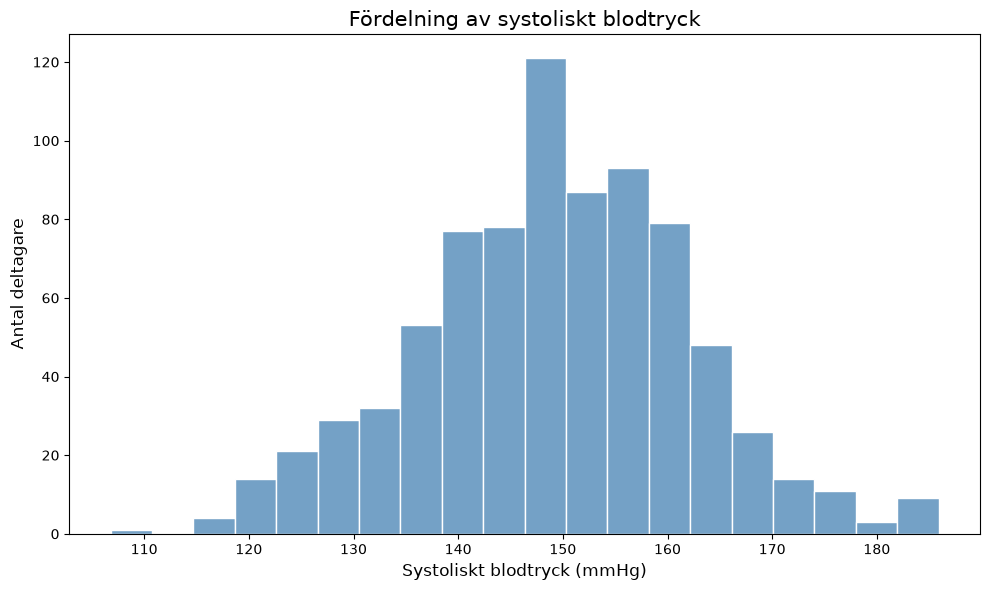

In [30]:
# garf 1: histogram över systoliskt blodtryck

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="systolic_bp",
    bins=20,
    color="steelblue",
    edgecolor="white"
)

plt.title("Fördelning av systoliskt blodtryck", fontsize=15)
plt.xlabel("Systoliskt blodtryck (mmHg)", fontsize=12)
plt.ylabel("Antal deltagare", fontsize=12)

plt.tight_layout()
plt.show()

### **Tolkning av graf 1**

histogrammet visar hur deltagarnas systoliska blodtryck är födelat. jag kam se att många av värdena ligger runt 140-160 mmHg, medan det är färre personer som har väldigt lågt eller högt blodtryck.

det ger mig en bättre bild av hur blodtrycket varierar mellan deltagarna.

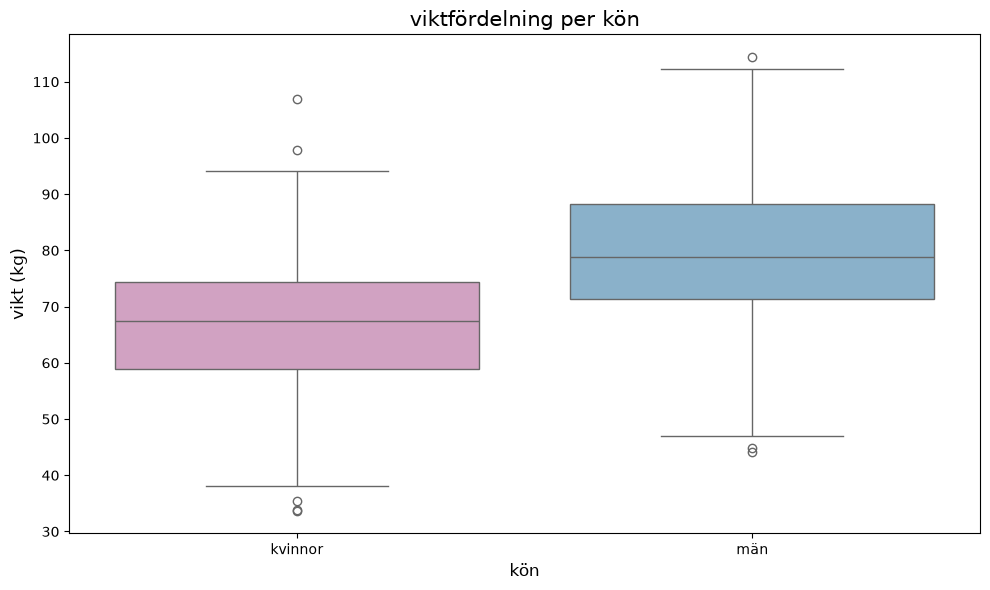

In [31]:
# graf 2: jämförelse av vikt mellan kvinnor och män

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="sex",
    y="weight",
    order=["F", "M"],
    hue="sex",
    palette={"F": "#D99AC5", "M": "#7FB3D5"},
    legend=False
)

plt.title("viktfördelning per kön", fontsize=15)
plt.xlabel("kön", fontsize=12)
plt.ylabel("vikt (kg)", fontsize=12)
plt.xticks([0, 1], ["kvinnor", "män"])

plt.tight_layout()
plt.show()

### **Tolkning av graf 2**

i den här grafen jämför jag vikten mellan kvinnor och män. boxploten gör det lättare att se medianvikten och hur mycket vikten varierar inom grupperna.

jag kan också undersöka om någon grupp har större spridning eller om det finns personer med vikter som skiljer sig mycket från resten.

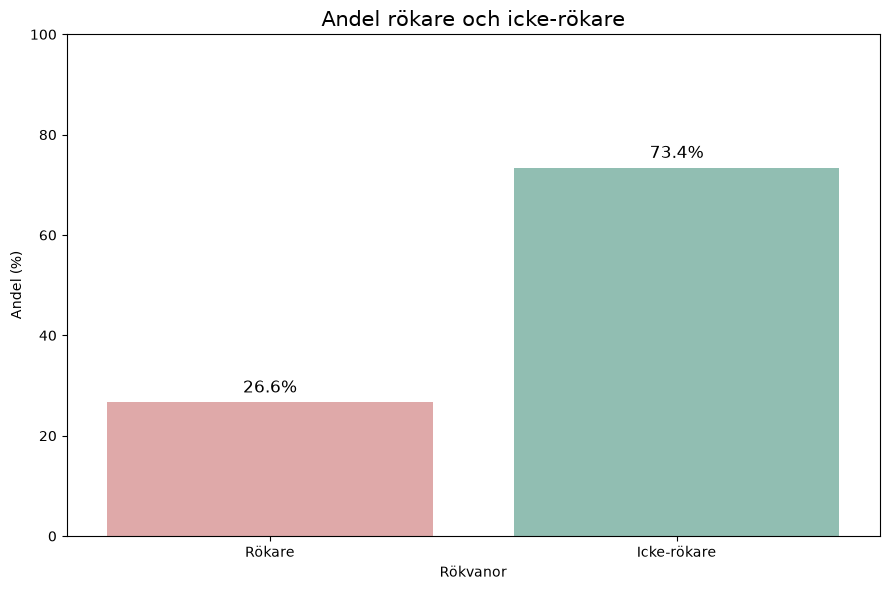

In [32]:
# graf 3: andelen rökare och icke-rökare 

rokare_procent = (
    df["smoker"]
    .value_counts(normalize=True)
    .reindex(["Yes", "No"])
    * 100
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=["Rökare", "Icke-rökare"],
    y=rokare_procent.values,
    hue=["Rökare", "Icke-rökare"],
    palette=["#E8A0A0", "#89C5B5"],
    legend=False
)

plt.title("Andel rökare och icke-rökare", fontsize=15)
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)

for i, procent in enumerate(rokare_procent.values):
    ax.text(i, procent + 2, f"{procent:.1f}%",
            ha="center", fontsize=12)

plt.tight_layout()
plt.show()

### **Tolkning av graf 3**

stapeldiagrammet visar att ungefär 26,6 % av deltagarna röker, medan 73,4 % inte röker.

det betyder att de flesta deltagarna i studien är icke-rökare. Jag tycker att det är intressant att se hur stor skillnaden är mellan grupperna.

den här informationen kan också vara användbar senare när jag ska undersöka om rökare har högre blodtryck än icke-rökare.

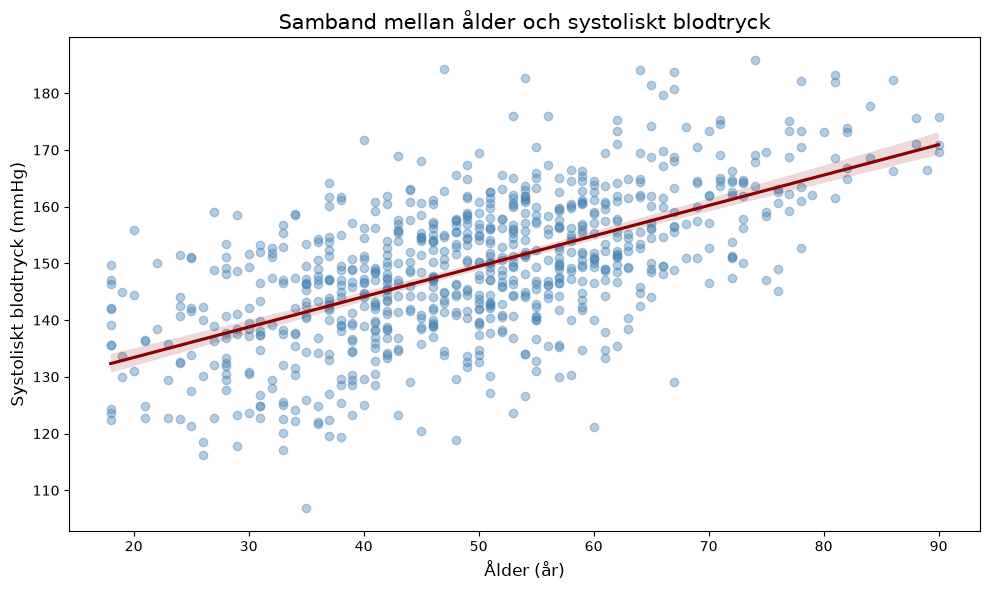

Korrelation: 0.61


In [33]:
# graf 4: samband mellan ålder och blodtryck

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="age",
    y="systolic_bp",
    scatter_kws={"alpha": 0.4, "color": "steelblue"},
    line_kws={"color": "darkred"}
)

plt.title("Samband mellan ålder och systoliskt blodtryck", fontsize=15)
plt.xlabel("Ålder (år)", fontsize=12)
plt.ylabel("Systoliskt blodtryck (mmHg)", fontsize=12)

plt.tight_layout()
plt.show()

# beräkna korrelationen
korrelation = df["age"].corr(df["systolic_bp"])

print(f"Korrelation: {korrelation:.2f}")


### **Tolkning av graf 4**

i den sista grafen undersöker jag om det finns något samband mellan ålder och systoliskt blodtryck.

jag kan se att blodtrycket generellt verkar öka med åldern. Korrelationen är ungefär 0,61, vilket visar ett ganska tydligt positivt samband.

det betyder att äldre personer i datasetet ofta har högre blodtryck, men det behöver inte betyda att åldern är den enda orsaken. Det kan finnas andra faktorer som också påverkar blodtrycket.

### **Sammanfattning av visualiseringarna**

efter att ha skapat graferna tycker jag att det har blivit lättare att förstå datasetet.

histogrammet visar hur blodtrycket är fördelat, medan boxploten hjälper mig att jämföra vikten mellan kvinnor och män. Stapeldiagrammet visar att de flesta deltagarna inte röker.

jag undersökte också sambandet mellan ålder och blodtryck och såg att det finns ett positivt samband mellan dessa variabler.

graferna hjälper mig att förstå datan bättre och ger en bra grund för de fortsatta analyserna.

# **3. Simulering med NumPy**

i den här delen ska jag använda NumPy för att simulera 1 000 personer och undersöka hur många som kan förväntas ha sjukdomen.

jag börjar med att räkna ut sjukdomsandelen i det riktiga datasetet. Sedan använder jag den andelen som sannolikhet i simuleringen.

efteråt jämför jag resultaten för att se hur mycket de skiljer sig åt.

In [34]:
import pandas as pd

# beräkna sjukdomsandelen i dtatasetet

# Ladda om data endast om df saknas
if "df" not in globals():
    df = pd.read_csv("data/health_study_dataset.csv")

antal_personer = len(df)

antal_sjuka = df["disease"].sum()

sjukdomsandel = df["disease"].mean()

print("Antal personer:", antal_personer)
print("Antal personer med sjukdom:", antal_sjuka)
print(f"Sjukdomsandel: {sjukdomsandel * 100:.2f}%")



Antal personer: 800
Antal personer med sjukdom: 47
Sjukdomsandel: 5.88%


In [35]:
import numpy as np

# simulera 1000 personer med NumPy

rng = np.random.default_rng(seed=42)

antal_simulerade = 1000

simulering = rng.binomial(
    n=1,
    p=sjukdomsandel,
    size=antal_simulerade
)

# beräkna resultatet 
simulerat_antal_sjuka = simulering.sum()
simulerad_andel = simulering.mean()

print("antal simulerade personer:", antal_simulerade)
print("antal personer med sjukdom:", simulerat_antal_sjuka)
print(f"simulerad sjukdomsandel: {simulerad_andel * 100:.2f}%")

antal simulerade personer: 1000
antal personer med sjukdom: 54
simulerad sjukdomsandel: 5.40%


In [36]:

# jämför verklig och simulerad sjukdomsandel

skillnad = abs(sjukdomsandel - simulerad_andel) * 100

print(f"verklig sjukdomsandel: {sjukdomsandel * 100:.2f}%")
print(f"simulerad sjukdomsandel: {simulerad_andel * 100:.2f}%")
print(f"skillnad: {skillnad:.2f} procentenheter")


verklig sjukdomsandel: 5.88%
simulerad sjukdomsandel: 5.40%
skillnad: 0.47 procentenheter


### **Resultat och reflektion**

i det riktiga datasetet hade 47 av 800 personer sjukdomen, vilket motsvarar ungefär 5,88 %.

när jag simulerade 1 000 personer med NumPy fick jag 54 personer med sjukdomen. Det motsvarar 5,40 %.

skillnaden mellan resultaten blev ungefär 0,47 procentenheter.

jag tycker att resultaten ligger ganska nära varandra. Det visar att simuleringen kan ge ett liknande resultat som den riktiga datan, även om det inte blir exakt samma värde varje gång.

skillnaden beror på att simuleringen använder slumpmässiga utfall. Jag har använt ett fast slumpfrö för att kunna få samma resultat när jag kör koden igen.

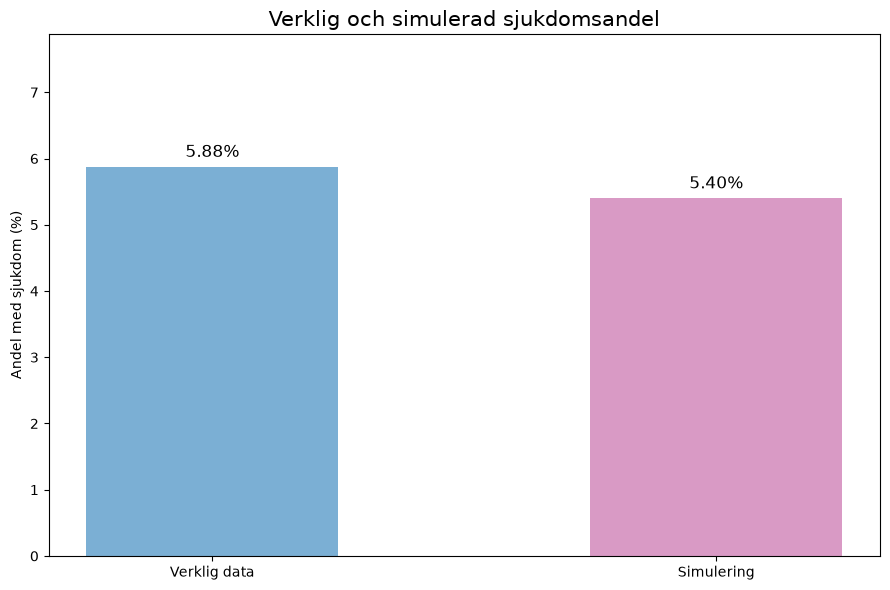

In [37]:

# graf: Verklig och simulerad sjukdomsandel

grupper = ["Verklig data", "Simulering"]

andelar = [
    sjukdomsandel * 100,
    simulerad_andel * 100
]
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))

bars = plt.bar(
    grupper,
    andelar,
    color=["#7BAFD4", "#D99AC5"],
    width=0.5
)

plt.title(
    "Verklig och simulerad sjukdomsandel",
    fontsize=15
)

plt.ylabel("Andel med sjukdom (%)")
plt.ylim(0, max(andelar) + 2)

for bar, andel in zip(bars, andelar):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{andel:.2f}%",
        ha="center",
        fontsize=12
    )

plt.tight_layout()
plt.show()


Genomsnittlig simulerad sjukdomsandel: 5.85%


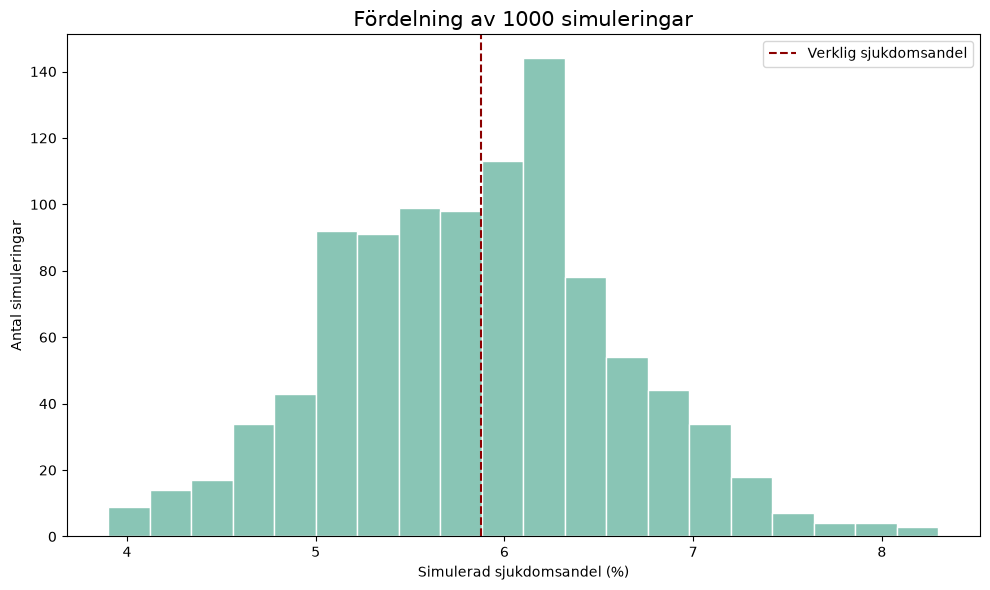

In [38]:

# extra analys: Upprepa simuleringen 1000 gånger

rng_extra = np.random.default_rng(42)

antal_forsok = 1000
personer_per_forsok = 1000

simulerade_antal = rng_extra.binomial(
    n=personer_per_forsok,
    p=sjukdomsandel,
    size=antal_forsok
)

simulerade_andelar = (
    simulerade_antal / personer_per_forsok * 100
)

print(
    "Genomsnittlig simulerad sjukdomsandel:",
    f"{simulerade_andelar.mean():.2f}%"
)

plt.figure(figsize=(10, 6))

plt.hist(
    simulerade_andelar,
    bins=20,
    color="#89C5B5",
    edgecolor="white"
)

plt.axvline(
    sjukdomsandel * 100,
    color="darkred",
    linestyle="--",
    label="Verklig sjukdomsandel"
)

plt.title("Fördelning av 1000 simuleringar", fontsize=15)
plt.xlabel("Simulerad sjukdomsandel (%)")
plt.ylabel("Antal simuleringar")
plt.legend()

plt.tight_layout()
plt.show()


### **Fördjupad analys av simuleringen**

jag valde också att upprepa simuleringen 1 000 gånger för att se hur mycket sjukdomsandelen kan variera.

resultaten blev inte exakt likadana varje gång, eftersom varje simulering innehåller slumpmässiga utfall.

när jag tittar på histogrammet ser jag att många av resultaten ligger nära sjukdomsandelen i det riktiga datasetet. Samtidigt finns det simuleringar som ger både högre och lägre andelar.

det visar att slumpen kan påverka resultatet, särskilt när man undersöker en begränsad grupp människor. Genom att upprepa simuleringen många gånger får jag en bättre bild av hur resultaten kan variera.

# **4. Konfidensintervall för sjukdomsandelen**

i den här delen ska jag beräkna ett 95 % konfidensintervall för sjukdomsandelen i datasetet.

jag använder två olika metoder: Wilson-metoden och bootstrap. Jag vill jämföra resultaten och se om metoderna ger ungefär samma intervall.

ett konfidensintervall hjälper mig att förstå hur osäker uppskattningen av sjukdomsandelen är.

In [39]:

# metod 1: Wilson-konfidensintervall

import numpy as np
from scipy.stats import norm

n = len(df)
p = df["disease"].mean()

# Z-värde för 95 % konfidensnivå
z = norm.ppf(0.975)

# Wilson-formeln
namnare = 1 + z**2 / n

mittpunkt = (
    p + z**2 / (2 * n)
) / namnare

felmarginal = (
    z / namnare
    * np.sqrt(
        p * (1 - p) / n
        + z**2 / (4 * n**2)
    )
)

wilson_nedre = mittpunkt - felmarginal
wilson_ovre = mittpunkt + felmarginal

print("Wilson-metoden:")
print(f"Nedre gräns: {wilson_nedre * 100:.2f}%")
print(f"Övre gräns: {wilson_ovre * 100:.2f}%")


Wilson-metoden:
Nedre gräns: 4.45%
Övre gräns: 7.73%


### **Tolkning av Wilson-metoden**

när jag använde Wilson-metoden fick jag ett 95 % konfidensintervall mellan ungefär 4,45 % och 7,73 %.

i själva datasetet är sjukdomsandelen 5,88 %, vilket ligger inom intervallet.

resultatet visar att det finns en viss osäkerhet kring uppskattningen. Om deltagarna är representativa för en större population kan intervallet hjälpa oss att uppskatta sjukdomsandelen i den populationen.

In [40]:

# metod 2: Bootstrap-konfidensintervall

rng = np.random.default_rng(42)

sjukdom_data = df["disease"].to_numpy()

antal_bootstrap = 10000
bootstrap_andelar = []

for i in range(antal_bootstrap):

    # Dra ett nytt stickprov med återläggning
    stickprov = rng.choice(
        sjukdom_data,
        size=len(sjukdom_data),
        replace=True
    )

    # Beräkna sjukdomsandelen
    andel = stickprov.mean()

    bootstrap_andelar.append(andel)

# Beräkna 95 % konfidensintervall
bootstrap_nedre = np.percentile(
    bootstrap_andelar, 2.5
)

bootstrap_ovre = np.percentile(
    bootstrap_andelar, 97.5
)

print("Bootstrap-metoden:")
print(f"Nedre gräns: {bootstrap_nedre * 100:.2f}%")
print(f"Övre gräns: {bootstrap_ovre * 100:.2f}%")


Bootstrap-metoden:
Nedre gräns: 4.38%
Övre gräns: 7.62%


### **Tolkning av bootstrap-metoden**

med bootstrap-metoden fick jag ett 95 % konfidensintervall mellan ungefär 4,38 % och 7,62 %.

jag skapade 10 000 nya stickprov från datasetet och beräknade sjukdomsandelen i varje stickprov.

sedan använde jag percentilerna 2,5 och 97,5 för att få intervallets nedre och övre gräns.

resultatet ligger nära Wilson-metodens intervall. Det visar att båda metoderna ger en liknande uppskattning av osäkerheten kring sjukdomsandelen.

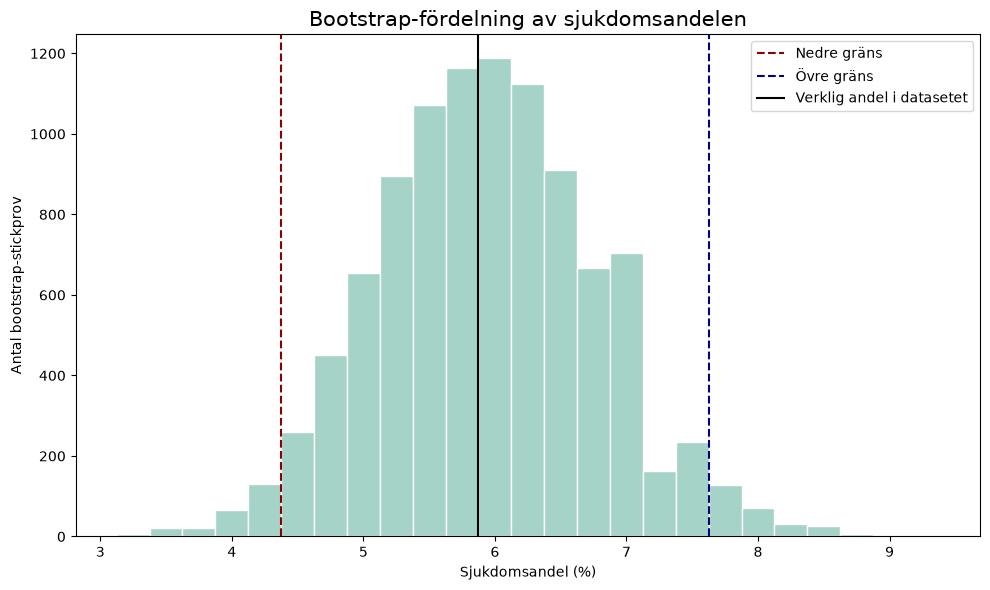

In [41]:

# visualisering av bootstrap-resultatet

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    np.array(bootstrap_andelar) * 100,
    bins=25,
    color="#89C5B5",
    edgecolor="white"
)

plt.axvline(
    bootstrap_nedre * 100,
    color="darkred",
    linestyle="--",
    label="Nedre gräns"
)

plt.axvline(
    bootstrap_ovre * 100,
    color="darkblue",
    linestyle="--",
    label="Övre gräns"
)

plt.axvline(
    p * 100,
    color="black",
    linestyle="-",
    label="Verklig andel i datasetet"
)

plt.title(
    "Bootstrap-fördelning av sjukdomsandelen",
    fontsize=15
)

plt.xlabel("Sjukdomsandel (%)")
plt.ylabel("Antal bootstrap-stickprov")

plt.legend()
plt.tight_layout()
plt.show()


### **Tolkning av bootstrap-grafen**

histogrammet visar hur sjukdomsandelen varierade mellan mina 10 000 bootstrap-stickprov.

jag kan se att många resultat ligger nära den ursprungliga sjukdomsandelen på 5,88 %. Det finns också stickprov där andelen blev lite högre eller lägre.

det streckade linjerna visar konfidensintervallets gränser.

grafen hjälper mig att förstå hur mycket resultatet kan variera när man tar nya stickprov från samma data.

In [42]:

# jämförelse av konfidensintervallen

import pandas as pd

jamforelse = pd.DataFrame({
    "Metod": ["Wilson", "Bootstrap"],
    "Nedre gräns (%)": [
        wilson_nedre * 100,
        bootstrap_nedre * 100
    ],
    "Övre gräns (%)": [
        wilson_ovre * 100,
        bootstrap_ovre * 100
    ]
})

display(jamforelse.round(2))


,Metod,Nedre gräns (%),Övre gräns (%)
0,Wilson,4.45,7.73
1,Bootstrap,4.38,7.62


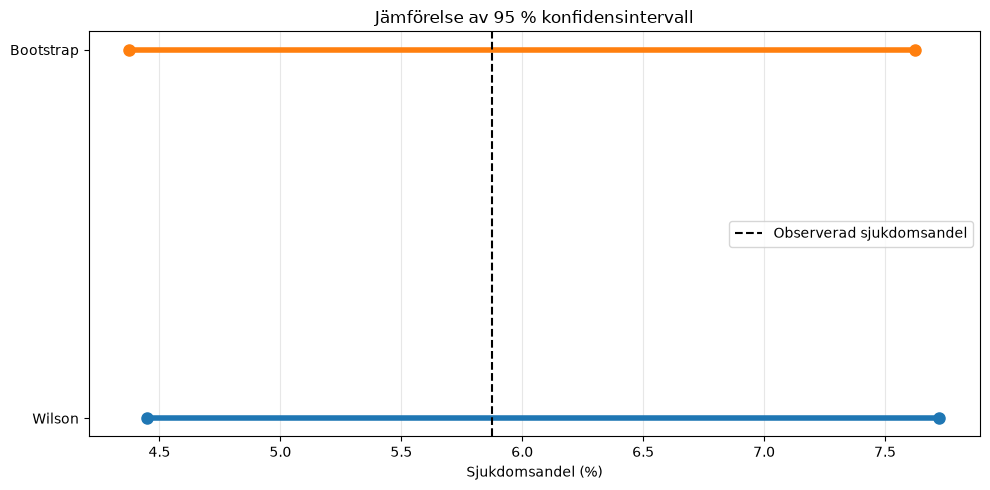

In [43]:

# jämför konfidensintervallen visuellt

plt.figure(figsize=(10, 5))

metoder = ["Wilson", "Bootstrap"]

nedre = [
    wilson_nedre * 100,
    bootstrap_nedre * 100
]

ovre = [
    wilson_ovre * 100,
    bootstrap_ovre * 100
]

for i in range(len(metoder)):
    plt.plot(
        [nedre[i], ovre[i]],
        [i, i],
        marker="o",
        linewidth=4,
        markersize=8
    )

plt.axvline(
    p * 100,
    color="black",
    linestyle="--",
    label="Observerad sjukdomsandel"
)

plt.yticks([0, 1], metoder)
plt.xlabel("Sjukdomsandel (%)")
plt.title("Jämförelse av 95 % konfidensintervall")

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### **Sammanfattning och jämförelse**

jag har beräknat ett 95 % konfidensintervall för sjukdomsandelen med två olika metoder.

ned Wilson-metoden fick jag ett intervall mellan 4,45 % och 7,73 %. Med bootstrap-metoden blev intervallet ungefär 4,38 % till 7,62 %.

resultaten är ganska lika, även om gränserna skiljer sig lite åt.

wilson-metoden använder en statistisk formel, medan bootstrap bygger på att man upprepar slumpmässiga stickprov från den data man redan har.

jag tycker att det är bra att använda två metoder eftersom jag då kan jämföra resultaten. Båda visar att den uppskattade sjukdomsandelen har en viss osäkerhet.

det är också viktigt att komma ihåg att ett konfidensintervall inte kan rätta till problem med exempelvis ett snedvridet urval. För att kunna dra slutsatser om en större population behöver deltagarna vara representativa för den populationen.

# **5. Hypotesprövning – Rökning och blodtryck**

i den här delen ska jag undersöka om personer som röker har högre genomsnittligt systoliskt blodtryck än personer som inte röker.

jag börjar med att jämföra medelvärdena mellan grupperna. Sedan använder jag ett statistiskt test för att undersöka om skillnaden är statistiskt signifikant.

jag använder en signifikansnivå på 5 %, vilket betyder att jag jämför testets p-värde med 0,05.

### **Hypoteser**

jag har valt att testa följande hypoteser:

**H₀ (nollhypotes):** rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare.

**H₁ (alternativhypotes):** rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

jag använder ett ensidigt test eftersom jag vill undersöka om blodtrycket är högre hos rökare, inte bara om det finns någon skillnad mellan grupperna.

In [44]:

# dela upp blodtrycket i två grupper

rokare = df.loc[
    df["smoker"] == "Yes", "systolic_bp"
].dropna()

icke_rokare = df.loc[
    df["smoker"] == "No", "systolic_bp"
].dropna()

# Beräkna medelvärdena
medel_rokare = rokare.mean()
medel_icke_rokare = icke_rokare.mean()

print("Antal rökare:", len(rokare))
print("Antal icke-rökare:", len(icke_rokare))

print(f"Medelblodtryck rökare: {medel_rokare:.2f} mmHg")
print(f"Medelblodtryck icke-rökare: {medel_icke_rokare:.2f} mmHg")

skillnad = medel_rokare - medel_icke_rokare

print(f"Skillnad: {skillnad:.2f} mmHg")


Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck icke-rökare: 149.05 mmHg
Skillnad: 0.47 mmHg


### **Jämförelse av medelvärden**

när jag jämför grupperna ser jag att rökare har ett genomsnittligt systoliskt blodtryck på ungefär 149,52 mmHg, medan icke-rökare har 149,05 mmHg.

skillnaden är alltså ungefär 0,47 mmHg.

rökarna har ett lite högre medelvärde i datasetet, men skillnaden är ganska liten. Därför vill jag göra ett statistiskt test för att se om det finns tillräckligt med stöd för min hypotes.

In [45]:

# hypotesprövning med Welchs t-test

from scipy.stats import ttest_ind

t_statistik, p_varde = ttest_ind(
    rokare,
    icke_rokare,
    equal_var=False,
    alternative="greater"
)

print(f"T-statistik: {t_statistik:.4f}")
print(f"P-värde: {p_varde:.4f}")

# Signifikansnivå
alpha = 0.05

if p_varde < alpha:
    print("Resultatet är statistiskt signifikant.")
    print("Vi förkastar nollhypotesen.")
else:
    print("Resultatet är inte statistiskt signifikant.")
    print("Vi kan inte förkasta nollhypotesen.")


T-statistik: 0.4503
P-värde: 0.3264
Resultatet är inte statistiskt signifikant.
Vi kan inte förkasta nollhypotesen.


### **Resultat av hypotesprövningen**

jag använde Welchs t-test för att undersöka om rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

testet gav ett p-värde på ungefär 0,3264. Eftersom det är högre än signifikansnivån 0,05 kan jag inte förkasta nollhypotesen.

det betyder att jag inte har tillräckligt med statistiskt stöd för att säga att rökare har högre genomsnittligt blodtryck än icke-rökare.

även om rökarna hade ett något högre medelvärde i datasetet var skillnaden liten och inte statistiskt signifikant.

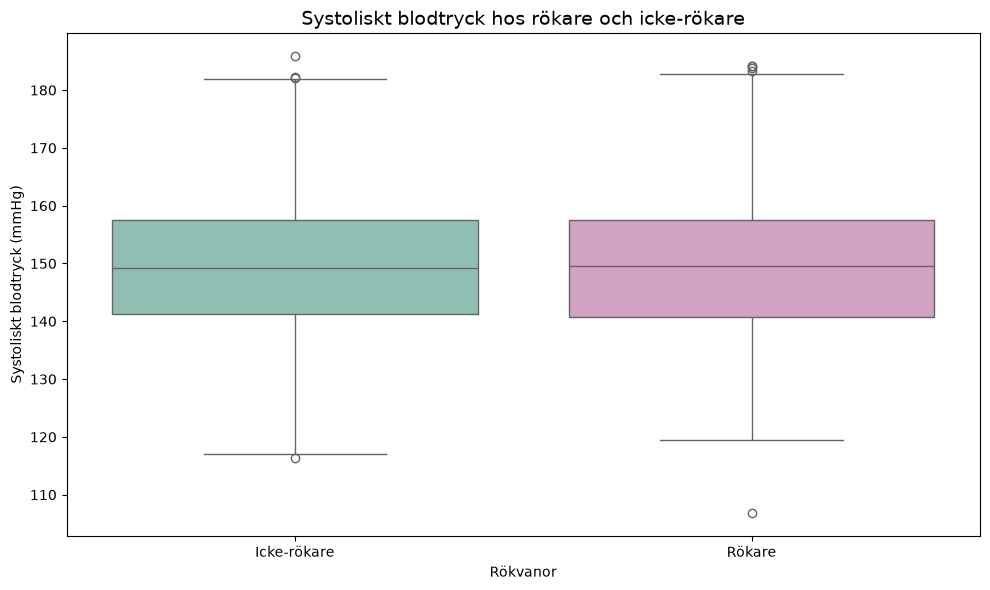

In [46]:

# visualisering av blodtryck hos rökare och icke-rökare

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="smoker",
    y="systolic_bp",
    order=["No", "Yes"],
    hue="smoker",
    palette={"No": "#89C5B5", "Yes": "#D99AC5"},
    legend=False
)

plt.title(
    "Systoliskt blodtryck hos rökare och icke-rökare",
    fontsize=14
)

plt.xlabel("Rökvanor")
plt.ylabel("Systoliskt blodtryck (mmHg)")
plt.xticks([0, 1], ["Icke-rökare", "Rökare"])

plt.tight_layout()
plt.show()


### **Tolkning av grafen**

boxploten visar hur det systoliska blodtrycket varierar mellan rökare och icke-rökare.

när jag jämför grupperna ser jag att deras blodtrycksfördelningar är ganska lika och överlappar mycket.

det stämmer bra med resultatet från hypotesprövningen, där jag inte hittade någon statistiskt signifikant skillnad i den riktning jag undersökte.

### **Motivering av metodval**

jag valde att använda Welchs t-test eftersom jag ville jämföra medelblodtrycket mellan två oberoende grupper.

tycker att metoden passar bra eftersom grupperna har olika många deltagare och jag inte behöver anta att deras varians är exakt lika.

valde också ett ensidigt test eftersom min hypotes handlar om att rökare har högre blodtryck än icke-rökare.

begränsning är att testet inte tar hänsyn till andra faktorer, som ålder och vikt. Därför kan jag inte dra slutsatsen att rökning orsakar en eventuell skillnad i blodtryck.

**Källa:** SciPy – `scipy.stats.ttest_ind`  
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

## **Sammanfattning av hypotesprövningen**

den här analysen undersökte jag om rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

började med att dela upp deltagarna i två grupper och jämförde deras medelvärden. Rökarna hade ett medelblodtryck på 149,52 mmHg och icke-rökarna hade 149,05 mmHg.

skillnaden var ungefär 0,47 mmHg.

jag genomförde Welchs t-test fick jag ett p-värde på 0,3264. Eftersom det är högre än 0,05 kunde jag inte förkasta nollhypotesen.

min slutsats är att det inte finns tillräckligt med statistiskt stöd i den här studien för att säga att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

nästa steg vill jag undersöka hur bra testet är på att upptäcka en verklig skillnad mellan grupperna genom att göra en power-simulering.

# **6. Power-simulering – Hur säkert är hypotestestet?**

den här delen ska jag undersöka hur bra mitt hypotestest är på att upptäcka en verklig skillnad i blodtryck mellan rökare och icke-rökare.

i den tidigare analysen hittade jag ingen statistiskt signifikant skillnad mellan grupperna. Därför tycker jag att det är intressant att undersöka om testet hade kunnat upptäcka en skillnad om den faktiskt fanns.

använder en simulering där jag skapar nya blodtrycksvärden och upprepar samma t-test många gånger. På så sätt kan jag uppskatta testets power.

In [52]:
# gförbered power-simuleringen

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Gör slumpen reproducerbar
rng = np.random.default_rng(42)

# Gruppstorlekar från datasetet
n_rokare = len(rokare)
n_icke_rokare = len(icke_rokare)

# Standardavvikelser från datasetet
std_rokare = rokare.std(ddof=1)
std_icke_rokare = icke_rokare.std(ddof=1)

# Antaganden för simuleringen
medel_icke_rokare = icke_rokare.mean()
verklig_skillnad = 5

medel_rokare_sim = (
    medel_icke_rokare + verklig_skillnad
)

antal_simuleringar = 1000
alpha = 0.05

print("Antal rökare:", n_rokare)
print("Antal icke-rökare:", n_icke_rokare)
print(f"Antagen skillnad: {verklig_skillnad} mmHg")
print("Antal simuleringar:", antal_simuleringar)


Antal rökare: 213
Antal icke-rökare: 587
Antagen skillnad: 5 mmHg
Antal simuleringar: 1000


In [53]:
# power-simulering med 1000 upprepade t-test

p_varden = []

for i in range(antal_simuleringar):

    # Simulera blodtryck hos rökare
    sim_rokare = rng.normal(
        loc=medel_rokare_sim,
        scale=std_rokare,
        size=n_rokare
    )

    # Simulera blodtryck hos icke-rökare
    sim_icke_rokare = rng.normal(
        loc=medel_icke_rokare,
        scale=std_icke_rokare,
        size=n_icke_rokare
    )

    # Genomför ensidigt Welch-test
    t_stat, p_varde_sim = ttest_ind(
        sim_rokare,
        sim_icke_rokare,
        equal_var=False,
        alternative="greater"
    )

    p_varden.append(p_varde_sim)

# Beräkna power
p_varden = np.array(p_varden)

antal_signifikanta = np.sum(p_varden < alpha)

power = antal_signifikanta / antal_simuleringar

print("Antal simuleringar:", antal_simuleringar)
print("Antal signifikanta resultat:", antal_signifikanta)
print(f"Uppskattad power: {power * 100:.1f}%")


Antal simuleringar: 1000
Antal signifikanta resultat: 998
Uppskattad power: 99.8%


### **Resultat från power-simuleringen**

genomförde 1 000 simuleringar för att undersöka hur ofta mitt hypotestest kan upptäcka en verklig skillnad i blodtryck.

antog att rökare i genomsnitt hade 5 mmHg högre blodtryck än icke-rökare. Jag använde samma gruppstorlekar och ungefär samma spridning som i mitt dataset.

resultatet visar att testet har mycket hög power för en skillnad på 5 mmHg med de här förutsättningarna.

det betyder att testet oftast skulle upptäcka en sådan skillnad om den verkligen fanns och antagandena i simuleringen stämmer.

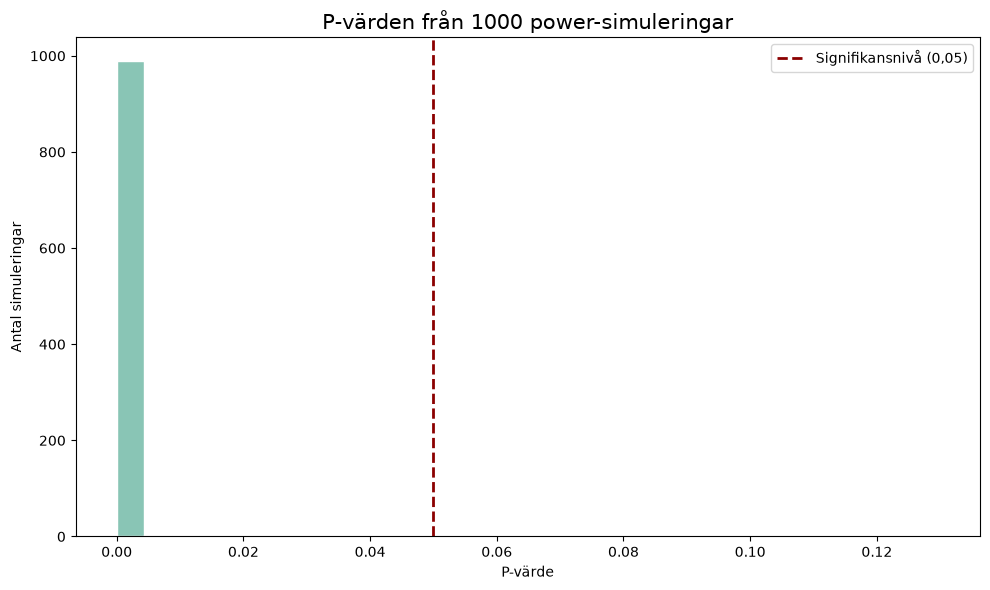

In [54]:
# visualisera p-värden från simuleringen

plt.figure(figsize=(10, 6))

plt.hist(
    p_varden,
    bins=30,
    color="#89C5B5",
    edgecolor="white"
)

plt.axvline(
    alpha,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Signifikansnivå (0,05)"
)

plt.title(
    "P-värden från 1000 power-simuleringar",
    fontsize=15
)

plt.xlabel("P-värde")
plt.ylabel("Antal simuleringar")

plt.legend()
plt.tight_layout()
plt.show()


### **tolkning av grafen**

histogrammet visar p-värdena från mina 1 000 simuleringar.

röda streckade linjen visar signifikansnivån 0,05. De p-värden som ligger till vänster om linjen räknas som statistiskt signifikanta.

jag simulerade en verklig skillnad på 5 mmHg hamnade nästan alla p-värden under 0,05.

det visar att testet har god förmåga att upptäcka en skillnad av den storleken under de antaganden jag har gjort.

In [55]:

# undersök power vid olika skillnader i blodtryck

rng_power = np.random.default_rng(123)

skillnader = [0, 1, 2, 3, 4, 5]
power_resultat = []

for effekt in skillnader:

    signifikanta = 0

    for i in range(1000):

        sim_rokare = rng_power.normal(
            loc=medel_icke_rokare + effekt,
            scale=std_rokare,
            size=n_rokare
        )

        sim_icke_rokare = rng_power.normal(
            loc=medel_icke_rokare,
            scale=std_icke_rokare,
            size=n_icke_rokare
        )

        _, p = ttest_ind(
            sim_rokare,
            sim_icke_rokare,
            equal_var=False,
            alternative="greater"
        )

        if p < 0.05:
            signifikanta += 1

    power_resultat.append(signifikanta / 1000)

# Visa resultaten i en tabell
import pandas as pd

power_tabell = pd.DataFrame({
    "Skillnad (mmHg)": skillnader,
    "Power (%)": np.array(power_resultat) * 100
})

display(power_tabell.round(1))


,Skillnad (mmHg),Power (%)
0,0,4.6
1,1,23.1
2,2,62.8
3,3,89.4
4,4,98.6
5,5,99.8


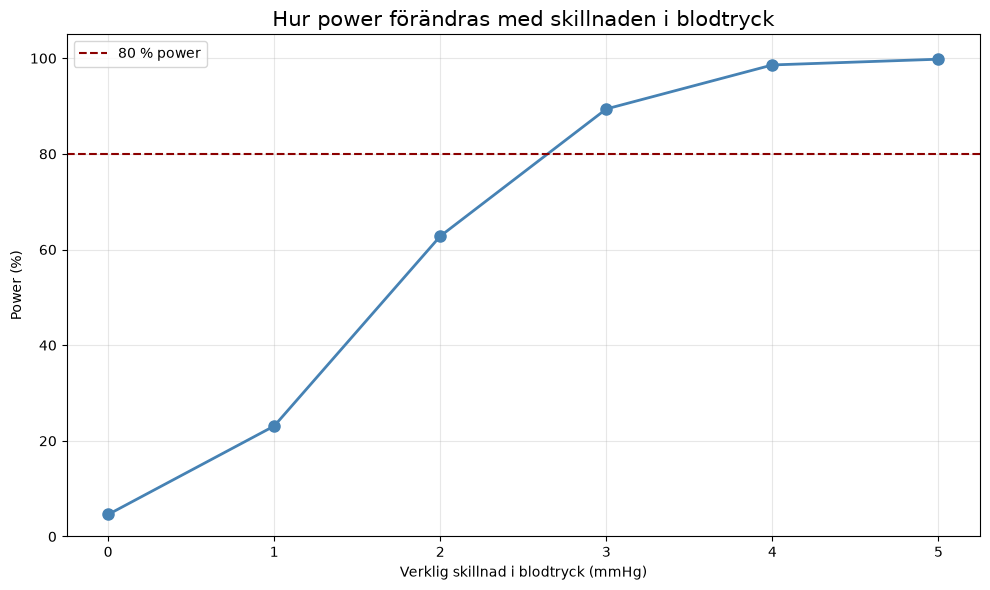

In [56]:

# rita en graf över power vid olika skillnader

plt.figure(figsize=(10, 6))

plt.plot(
    skillnader,
    np.array(power_resultat) * 100,
    marker="o",
    color="steelblue",
    linewidth=2,
    markersize=8
)

plt.axhline(
    80,
    color="darkred",
    linestyle="--",
    label="80 % power"
)

plt.title(
    "Hur power förändras med skillnaden i blodtryck",
    fontsize=15
)

plt.xlabel("Verklig skillnad i blodtryck (mmHg)")
plt.ylabel("Power (%)")
plt.ylim(0, 105)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### **Fördjupad analys – Skillnadens betydelse**

ville också undersöka hur testets power förändras beroende på hur stor skillnaden i blodtryck är.

därför gjorde jag flera simuleringar med skillnader mellan 0 och 5 mmHg.

resultatet visar att testets power generellt ökar när skillnaden mellan grupperna blir större.

skillnaden är liten är det svårare för testet att upptäcka den. När skillnaden blir större ökar sannolikheten att få ett statistiskt signifikant resultat.

här hjälper mig att förstå varför ett hypotestest ibland inte hittar någon signifikant skillnad, även om det kan finnas en verklig skillnad mellan grupperna.

### **Motivering av metodval**

valde att använda en power-simulering eftersom jag ville undersöka hur bra mitt hypotestest är på att upptäcka verkliga skillnader.

använde NumPy för att skapa simulerade blodtrycksvärden och SciPy för att genomföra Welchs t-test.

jag använde samma antal deltagare och standardavvikelser som i mitt riktiga dataset. Däremot bestämde jag själv vilka skillnader i medelblodtryck jag ville undersöka.

antog att blodtrycket var normalfördelat inom grupperna och att observationerna var oberoende. Resultaten gäller därför under de antagandena.

jag använde också fasta slumpfrön för att göra analysen reproducerbar.

**Källor:**

- NumPy – Normalfördelning: https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html
- SciPy – Welchs t-test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

### **Sammanfattning av power-simuleringen**

den här delen har jag undersökt hur bra mitt hypotestest är på att upptäcka skillnader i blodtryck mellan rökare och icke-rökare.

började med att simulera en skillnad på 5 mmHg och upprepade testet 1 000 gånger.

simuleringen visade att testet har mycket hög power för att upptäcka en sådan skillnad med de gruppstorlekar jag använde.

undersökte också mindre skillnader och såg att testets power generellt minskar när skillnaden blir mindre.

här är viktigt när jag tolkar mitt tidigare hypotestest. Att jag inte hittade någon statistiskt signifikant skillnad betyder inte automatiskt att grupperna har exakt samma blodtryck.

min slutsats är att power-simuleringen hjälper mig att förstå både möjligheterna och begränsningarna med hypotesprövningen.

# **7. Konfidensintervall för medelvärdet av systoliskt blodtryck**

den här delen ska jag beräkna ett 95 % konfidensintervall för det genomsnittliga systoliska blodtrycket.

jag använder två olika metoder: ett t-baserat konfidensintervall och bootstrap.

vill jämföra resultaten och undersöka om metoderna ger ungefär samma uppskattning.

In [57]:
import numpy as np
from scipy import stats

# Hämta blodtrycksvärden
blodtryck = df["systolic_bp"].dropna()

# Beräkna grundläggande statistik
n = len(blodtryck)
medel = blodtryck.mean()
std = blodtryck.std(ddof=1)

# Beräkna standardfel
standardfel = std / np.sqrt(n)

# 95 % t-baserat konfidensintervall
t_nedre, t_ovre = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=medel,
    scale=standardfel
)

print(f"Antal deltagare: {n}")
print(f"Medelblodtryck: {medel:.2f} mmHg")
print(f"Standardavvikelse: {std:.2f} mmHg")
print(f"95 % KI (t-metod): {t_nedre:.2f}–{t_ovre:.2f} mmHg")


Antal deltagare: 800
Medelblodtryck: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
95 % KI (t-metod): 148.29–150.07 mmHg


In [58]:

# Bootstrap för medelvärdet av blodtryck

rng_bp = np.random.default_rng(42)

antal_bootstrap_bp = 10000
bootstrap_medel = []

for i in range(antal_bootstrap_bp):

    stickprov = rng_bp.choice(
        blodtryck.to_numpy(),
        size=len(blodtryck),
        replace=True
    )

    bootstrap_medel.append(stickprov.mean())

bootstrap_medel = np.array(bootstrap_medel)

bp_nedre = np.percentile(bootstrap_medel, 2.5)
bp_ovre = np.percentile(bootstrap_medel, 97.5)

print(f"95 % KI (bootstrap): {bp_nedre:.2f}–{bp_ovre:.2f} mmHg")


95 % KI (bootstrap): 148.31–150.05 mmHg


,Metod,Nedre gräns (mmHg),Övre gräns (mmHg)
0,t-baserat,148.29,150.07
1,Bootstrap,148.31,150.05


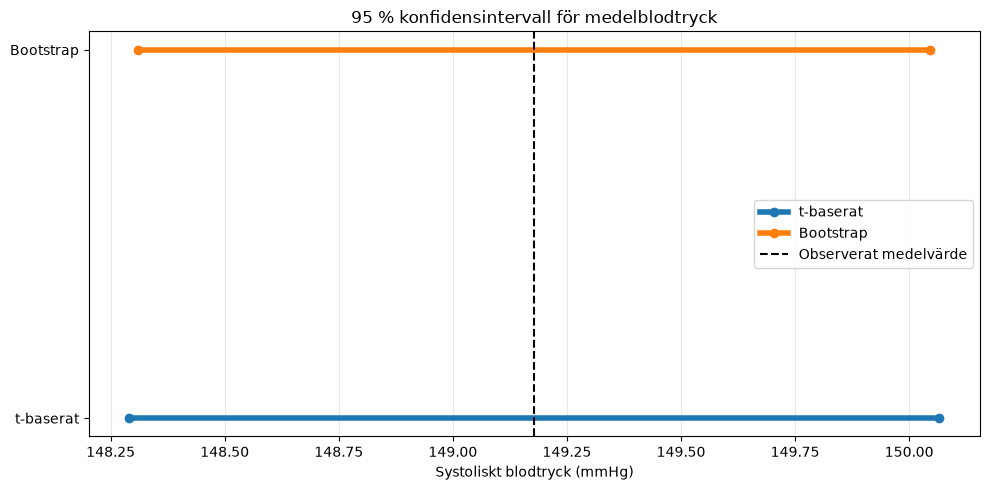

In [59]:
# Jämförelse mellan metoderna

jamforelse_bp = pd.DataFrame({
    "Metod": ["t-baserat", "Bootstrap"],
    "Nedre gräns (mmHg)": [t_nedre, bp_nedre],
    "Övre gräns (mmHg)": [t_ovre, bp_ovre]
})

display(jamforelse_bp.round(2))

# Visualisering
plt.figure(figsize=(10, 5))

plt.plot(
    [t_nedre, t_ovre],
    [0, 0],
    marker="o",
    linewidth=4,
    label="t-baserat"
)

plt.plot(
    [bp_nedre, bp_ovre],
    [1, 1],
    marker="o",
    linewidth=4,
    label="Bootstrap"
)

plt.axvline(
    medel,
    color="black",
    linestyle="--",
    label="Observerat medelvärde"
)

plt.yticks([0, 1], ["t-baserat", "Bootstrap"])
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.title("95 % konfidensintervall för medelblodtryck")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### **Resultat och jämförelse**

har beräknat ett 95 % konfidensintervall för det genomsnittliga systoliska blodtrycket med två olika metoder.

den första metoden bygger på t-fördelningen och använder medelvärdet, standardavvikelsen och antalet deltagare.

andra metoden är bootstrap, där jag skapade 10 000 nya stickprov från den ursprungliga datan.

jag jämför intervallen kan jag se hur lika resultaten blir trots att metoderna fungerar på olika sätt.

valde t-metoden eftersom den passar när man vill uppskatta ett medelvärde och inte känner till populationens standardavvikelse. Bootstrap valde jag eftersom den ger möjlighet att uppskatta osäkerheten genom upprepade stickprov.

dåda metoderna förutsätter att datan ger en rimlig bild av den population jag vill undersöka. Bootstrap kan inte heller rätta till ett snedvridet urval.

**Källor:**

- SciPy – t-fördelning: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html
- NumPy – Random Generator: https://numpy.org/doc/stable/reference/random/generator.html